# Tugas Praktikum 3
## Classification dengan Ensemble Method dan Class Imbalance

**Nama:** Hilal Tsabitul Azmi Arbai  
**NRP:** 5054251008  
**Kelas:** N

---

## Tujuan Praktikum

Praktikum ini bertujuan untuk membangun model klasifikasi ensemble
menggunakan Random Forest pada dataset dengan distribusi kelas tidak
seimbang. Penanganan class imbalance dilakukan menggunakan SMOTE.
Performa Random Forest tanpa SMOTE dan Random Forest dengan SMOTE
dibandingkan berdasarkan precision, recall, F1-score, ROC-AUC, PR-AUC,
dan confusion matrix.

In [53]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    RocCurveDisplay,
    precision_recall_curve,
    average_precision_score
)
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE


In [54]:
df = pd.read_csv("creditcard.csv")

In [55]:
df.head(10)

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0
5,2.0,-0.425966,0.960523,1.141109,-0.168252,0.420987,-0.029728,0.476201,0.260314,-0.568671,...,-0.208254,-0.559825,-0.026398,-0.371427,-0.232794,0.105915,0.253844,0.081080,3.67,0
6,4.0,1.229658,0.141004,0.045371,1.202613,0.191881,0.272708,-0.005159,0.081213,0.464960,...,-0.167716,-0.270710,-0.154104,-0.780055,0.750137,-0.257237,0.034507,0.005168,4.99,0
7,7.0,-0.644269,1.417964,1.074380,-0.492199,0.948934,0.428118,1.120631,-3.807864,0.615375,...,1.943465,-1.015455,0.057504,-0.649709,-0.415267,-0.051634,-1.206921,-1.085339,40.80,0
8,7.0,-0.894286,0.286157,-0.113192,-0.271526,2.669599,3.721818,0.370145,0.851084,-0.392048,...,-0.073425,-0.268092,-0.204233,1.011592,0.373205,-0.384157,0.011747,0.142404,93.20,0
9,9.0,-0.338262,1.119593,1.044367,-0.222187,0.499361,-0.246761,0.651583,0.069539,-0.736727,...,-0.246914,-0.633753,-0.120794,-0.385050,-0.069733,0.094199,0.246219,0.083076,3.68,0


In [56]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [57]:
df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.168375e-15,3.416908e-16,-1.379537e-15,2.074095e-15,9.604066e-16,1.487313e-15,-5.556467e-16,1.213481e-16,-2.406331e-15,...,1.654067e-16,-3.568593e-16,2.578648e-16,4.473266e-15,5.340915e-16,1.683437e-15,-3.660091e-16,-1.227390e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


In [58]:
display(df.isnull().sum())

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

In [59]:
display(df.duplicated().sum())

np.int64(1081)

In [60]:
duplicate_by_class = df[df.duplicated(keep=False)]["Class"].value_counts()
duplicate_by_class

Class
0    1822
1      32
Name: count, dtype: int64

Pemeriksaan kualitas data dilakukan dengan mengidentifikasi missing value
dan data duplikat. Data duplikat tidak langsung dihapus karena transaksi
yang memiliki nilai fitur identik belum tentu merupakan kesalahan data.
Selain itu, penghapusan data harus dilakukan secara hati-hati agar tidak
mengurangi jumlah sampel pada kelas fraud yang sudah sangat sedikit.

In [61]:
class_count = df["Class"].value_counts().sort_index()
class_percentage = df["Class"].value_counts(
    normalize=True
).sort_index() * 100

distribution_df = pd.DataFrame({
    "Jumlah": class_count,
    "Persentase (%)": class_percentage
})

distribution_df.index = ["Normal (0)", "Fraud (1)"]
display(distribution_df)

,Jumlah,Persentase (%)
Normal (0),284315,99.827251
Fraud (1),492,0.172749


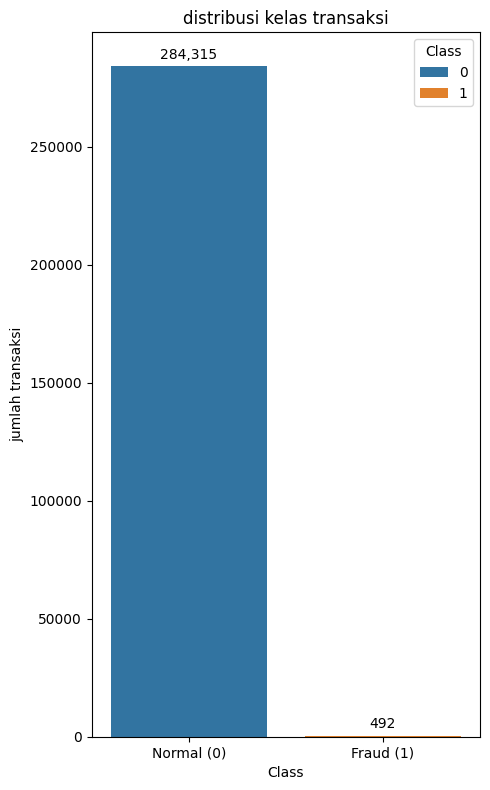

In [62]:
plt.figure(figsize=(5,8))
ax = sns.countplot(
    data=df,
    x="Class",
    hue="Class",
)

plt.title("distribusi kelas transaksi")
plt.xlabel("Class")
plt.ylabel("jumlah transaksi")
plt.xticks([0, 1], ["Normal (0)", "Fraud (1)"])

for container in ax.containers:
    ax.bar_label(container, fmt="{:,.0f}", padding=3)
    
plt.tight_layout()
plt.show()

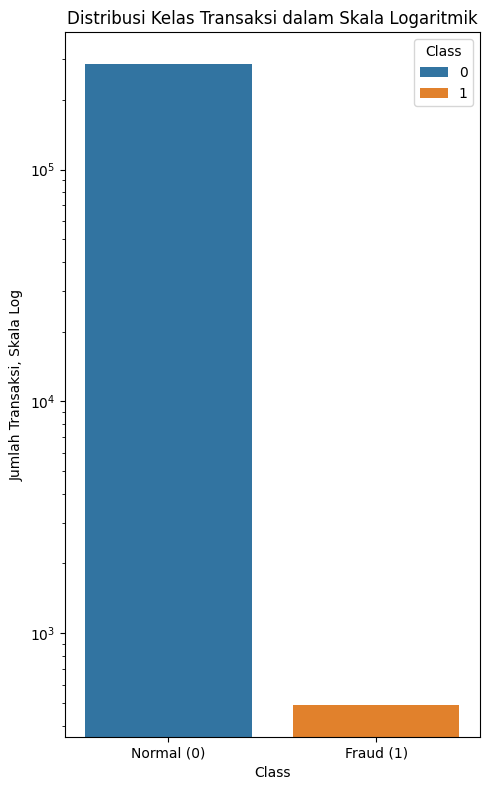

In [63]:
plt.figure(figsize=(5,8))
ax = sns.countplot(
    data=df,
    x="Class",
    hue="Class",
)
plt.yscale("log")
plt.title("Distribusi Kelas Transaksi dalam Skala Logaritmik")
plt.xlabel("Class")
plt.ylabel("Jumlah Transaksi, Skala Log")
plt.xticks([0, 1], ["Normal (0)", "Fraud (1)"])
plt.tight_layout()
plt.show()

Distribusi target menunjukkan bahwa jumlah transaksi normal jauh lebih
besar dibandingkan transaksi fraud. Kondisi ini menunjukkan adanya class
imbalance yang sangat tinggi. Model yang dilatih secara langsung pada data
tersebut berpotensi lebih sering memprediksi kelas mayoritas karena kelas
normal mendominasi data pelatihan.

Oleh karena itu, performa model tidak cukup dinilai menggunakan accuracy.
Evaluasi perlu difokuskan pada precision, recall, F1-score, dan AUC-ROC,
khususnya untuk kelas fraud sebagai kelas minoritas.

In [64]:
x = df.drop(columns="Class")
y = df["Class"].copy()

x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

Dataset dibagi menjadi 80% data latih dan 20% data uji. Parameter
`stratify=y` digunakan agar proporsi transaksi normal dan fraud pada data
latih serta data uji tetap mendekati distribusi kelas pada dataset awal.

Data uji tidak akan melalui proses SMOTE karena data uji digunakan untuk
mensimulasikan distribusi data yang sebenarnya. 

In [65]:
scaler = StandardScaler()

x_train_scaler = scaler.fit_transform(x_train)
x_test_scaler = scaler.transform(x_test)

In [66]:
def evaluate_model(model_name, model, X_test, y_test):
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]

    precision = precision_score(y_test, y_pred, pos_label=1)
    recall = recall_score(y_test, y_pred, pos_label=1)
    f1 = f1_score(y_test, y_pred, pos_label=1)
    roc_auc = roc_auc_score(y_test, y_proba)
    average_precision = average_precision_score(y_test, y_proba)

    print("=" * 70)
    print(model_name)
    print("=" * 70)

    print("\nClassification Report:")
    print(
        classification_report(
            y_test,
            y_pred,
            target_names=["Normal", "Fraud"],
            digits=4
        )
    )

    print(f"Precision Fraud : {precision:.4f}")
    print(f"Recall Fraud    : {recall:.4f}")
    print(f"F1-score Fraud  : {f1:.4f}")
    print(f"ROC-AUC         : {roc_auc:.4f}")
    print(f"PR-AUC          : {average_precision:.4f}")

    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(6, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt=",d",
        cmap="Blues",
        xticklabels=["Normal", "Fraud"],
        yticklabels=["Normal", "Fraud"]
    )

    plt.title(f"Confusion Matrix\n{model_name}")
    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")
    plt.tight_layout()
    plt.show()

    return {
        "Model": model_name,
        "Precision Fraud": precision,
        "Recall Fraud": recall,
        "F1-score Fraud": f1,
        "ROC-AUC": roc_auc,
        "PR-AUC": average_precision,
        "TN": cm[0, 0],
        "FP": cm[0, 1],
        "FN": cm[1, 0],
        "TP": cm[1, 1],
        "y_pred": y_pred,
        "y_proba": y_proba
    }

In [67]:
rf_baseline = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

In [68]:
rf_baseline.fit(x_train_scaler, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


RandomForestClassifier tanpa smote

Classification Report:
              precision    recall  f1-score   support

      Normal     0.9997    0.9999    0.9998     56864
       Fraud     0.9412    0.8163    0.8743        98

    accuracy                         0.9996     56962
   macro avg     0.9704    0.9081    0.9371     56962
weighted avg     0.9996    0.9996    0.9996     56962

Precision Fraud : 0.9412
Recall Fraud    : 0.8163
F1-score Fraud  : 0.8743
ROC-AUC         : 0.9630
PR-AUC          : 0.8734


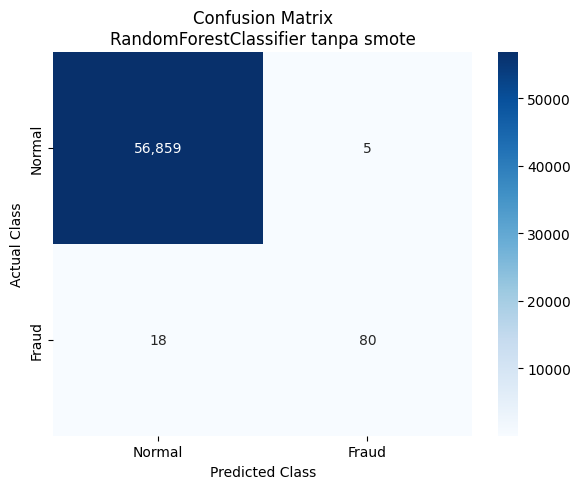

In [69]:
hasil_rf_baseline = evaluate_model(
    model_name="RandomForestClassifier tanpa smote",
    model=rf_baseline,
    X_test=x_test_scaler,
    y_test=y_test
)

In [70]:
smote = SMOTE(
    sampling_strategy=0.1,
    random_state=42
)

In [71]:
x_train_smote, y_train_smote = smote.fit_resample(
    x_train_scaler,
    y_train
)

In [72]:
print("Distribusi sebelum SMOTE:")
print(y_train.value_counts().sort_index())

print("\nDistribusi setelah SMOTE:")
print(pd.Series(y_train_smote).value_counts().sort_index())

Distribusi sebelum SMOTE:
Class
0    227451
1       394
Name: count, dtype: int64

Distribusi setelah SMOTE:
Class
0    227451
1     22745
Name: count, dtype: int64


Penanganan class imbalance dilakukan menggunakan Synthetic Minority
Over-sampling Technique atau SMOTE. Teknik ini membuat sampel sintetis
untuk kelas minoritas berdasarkan kedekatan antarobservasi kelas fraud.

Pada eksperimen ini digunakan `sampling_strategy=0.1`, sehingga jumlah
sampel fraud setelah proses SMOTE menjadi sekitar 10% dari jumlah sampel
normal. Rasio tersebut dipilih untuk meningkatkan representasi kelas fraud
tanpa menghasilkan sampel sintetis dalam jumlah yang terlalu besar.

SMOTE hanya diterapkan pada data latih. Data uji tetap menggunakan
distribusi kelas asli agar hasil evaluasi menggambarkan kemampuan model
ketika menghadapi kondisi data yang sebenarnya.

In [73]:
rf_smote = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_smote.fit(x_train_smote, y_train_smote)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


Random Forest dengan SMOTE

Classification Report:
              precision    recall  f1-score   support

      Normal     0.9997    0.9998    0.9998     56864
       Fraud     0.8817    0.8367    0.8586        98

    accuracy                         0.9995     56962
   macro avg     0.9407    0.9183    0.9292     56962
weighted avg     0.9995    0.9995    0.9995     56962

Precision Fraud : 0.8817
Recall Fraud    : 0.8367
F1-score Fraud  : 0.8586
ROC-AUC         : 0.9642
PR-AUC          : 0.8784


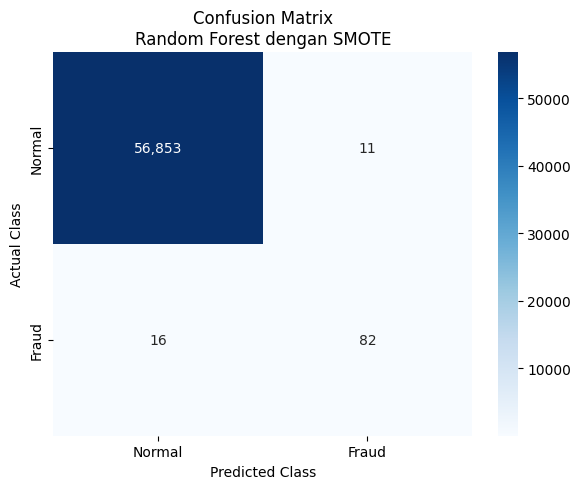

In [74]:
result_smote = evaluate_model(
    model_name="Random Forest dengan SMOTE",
    model=rf_smote,
    X_test=x_test_scaler,
    y_test=y_test
)

In [75]:
comparison_results = pd.DataFrame([
    {
        "Model": hasil_rf_baseline["Model"],
        "Precision Fraud": hasil_rf_baseline["Precision Fraud"],
        "Recall Fraud": hasil_rf_baseline["Recall Fraud"],
        "F1-score Fraud": hasil_rf_baseline["F1-score Fraud"],
        "ROC-AUC": hasil_rf_baseline["ROC-AUC"],
        "PR-AUC": hasil_rf_baseline["PR-AUC"],
        "False Positive": hasil_rf_baseline["FP"],
        "False Negative": hasil_rf_baseline["FN"],
        "True Positive": hasil_rf_baseline["TP"]
    },
    {
        "Model": result_smote["Model"],
        "Precision Fraud": result_smote["Precision Fraud"],
        "Recall Fraud": result_smote["Recall Fraud"],
        "F1-score Fraud": result_smote["F1-score Fraud"],
        "ROC-AUC": result_smote["ROC-AUC"],
        "PR-AUC": result_smote["PR-AUC"],
        "False Positive": result_smote["FP"],
        "False Negative": result_smote["FN"],
        "True Positive": result_smote["TP"]
    }
])

comparison_results.round(4)

,Model,Precision Fraud,Recall Fraud,F1-score Fraud,ROC-AUC,PR-AUC,False Positive,False Negative,True Positive
0,RandomForestClassifier tanpa smote,0.9412,0.8163,0.8743,0.9630,0.8734,5,18,80
1,Random Forest dengan SMOTE,0.8817,0.8367,0.8586,0.9642,0.8784,11,16,82


### Analisis Random Forest Tanpa SMOTE

Random Forest tanpa SMOTE menghasilkan precision fraud sebesar 0,9412,
recall sebesar 0,8163, F1-score sebesar 0,8743, ROC-AUC sebesar 0,9630,
dan PR-AUC sebesar 0,8734.

Berdasarkan confusion matrix, model berhasil mendeteksi 80 dari 98
transaksi fraud. Sebanyak 18 transaksi fraud masih salah diprediksi
sebagai transaksi normal, sedangkan 5 transaksi normal salah diprediksi
sebagai fraud. Precision yang tinggi menunjukkan bahwa sebagian besar
prediksi fraud yang diberikan model merupakan transaksi fraud sebenarnya.
Namun, recall sebesar 0,8163 menunjukkan bahwa masih terdapat fraud yang
tidak terdeteksi.

### Analisis Random Forest Tanpa SMOTE

Random Forest tanpa SMOTE menghasilkan precision fraud sebesar 0,9412,
recall sebesar 0,8163, F1-score sebesar 0,8743, ROC-AUC sebesar 0,9630,
dan PR-AUC sebesar 0,8734.

Berdasarkan confusion matrix, model berhasil mendeteksi 80 dari 98
transaksi fraud. Sebanyak 18 transaksi fraud masih salah diprediksi
sebagai transaksi normal, sedangkan 5 transaksi normal salah diprediksi
sebagai fraud. Precision yang tinggi menunjukkan bahwa sebagian besar
prediksi fraud yang diberikan model merupakan transaksi fraud sebenarnya.
Namun, recall sebesar 0,8163 menunjukkan bahwa masih terdapat fraud yang
tidak terdeteksi.

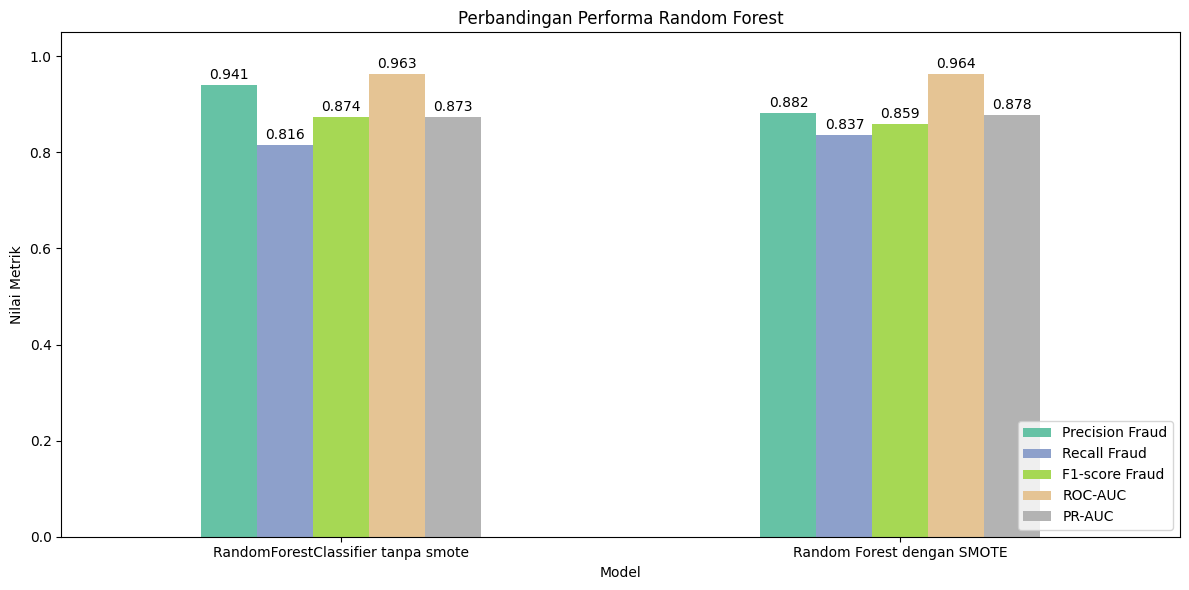

In [76]:
metrics_to_plot = [
    "Precision Fraud",
    "Recall Fraud",
    "F1-score Fraud",
    "ROC-AUC",
    "PR-AUC"
]

plot_df = comparison_results.set_index("Model")[metrics_to_plot]

ax = plot_df.plot(
    kind="bar",
    figsize=(12, 6),
    colormap="Set2"
)

plt.title("Perbandingan Performa Random Forest")
plt.xlabel("Model")
plt.ylabel("Nilai Metrik")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc="lower right")

for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=2)

plt.tight_layout()
plt.show()

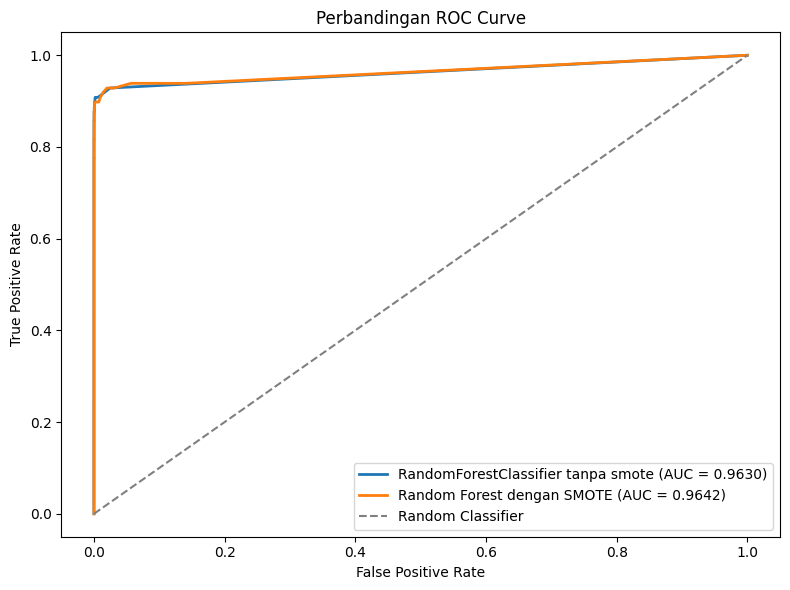

In [77]:
plt.figure(figsize=(8, 6))

for result in [hasil_rf_baseline, result_smote]:
    fpr, tpr, _ = roc_curve(y_test, result["y_proba"])

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=(
            f'{result["Model"]} '
            f'(AUC = {result["ROC-AUC"]:.4f})'
        )
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random Classifier"
)

plt.title("Perbandingan ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.tight_layout()
plt.show()

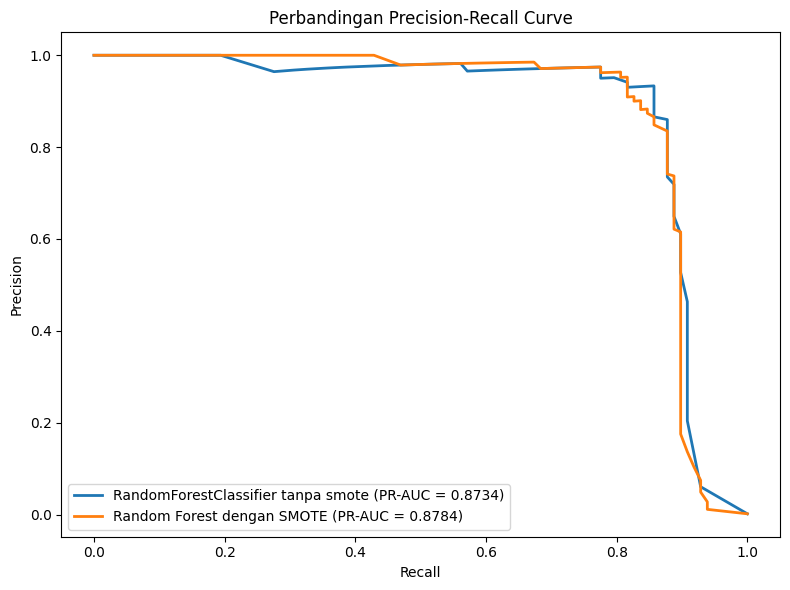

In [78]:
plt.figure(figsize=(8, 6))

for result in [hasil_rf_baseline, result_smote]:
    precision_values, recall_values, _ = precision_recall_curve(
        y_test,
        result["y_proba"]
    )

    plt.plot(
        recall_values,
        precision_values,
        linewidth=2,
        label=(
            f'{result["Model"]} '
            f'(PR-AUC = {result["PR-AUC"]:.4f})'
        )
    )

plt.title("Perbandingan Precision-Recall Curve")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend()
plt.tight_layout()
plt.show()

## Analisis Perbandingan Model

Penerapan SMOTE meningkatkan recall fraud dari 0,8163 menjadi 0,8367.
Peningkatan tersebut disertai kenaikan true positive dari 80 menjadi 82
dan penurunan false negative dari 18 menjadi 16. Artinya, model dengan
SMOTE berhasil mendeteksi dua transaksi fraud tambahan.

Namun, precision fraud menurun dari 0,9412 menjadi 0,8817 karena false
positive meningkat dari 5 menjadi 11. F1-score juga menurun dari 0,8743
menjadi 0,8586. Dengan demikian, peningkatan recall diperoleh dengan
konsekuensi berupa bertambahnya transaksi normal yang salah ditandai
sebagai fraud.

Nilai ROC-AUC kedua model relatif berdekatan, yaitu 0,9630 pada model
tanpa SMOTE dan 0,9642 pada model dengan SMOTE. PR-AUC meningkat dari
0,8734 menjadi 0,8784. Hasil ini menunjukkan bahwa kemampuan umum kedua
model dalam memisahkan kelas relatif serupa, tetapi model dengan SMOTE
sedikit lebih sensitif terhadap kelas fraud.

Apabila tujuan utama sistem adalah mengurangi transaksi fraud yang tidak
terdeteksi, Random Forest dengan SMOTE lebih sesuai karena menghasilkan
recall lebih tinggi dan false negative lebih rendah. Namun, apabila
keseimbangan precision dan recall menjadi pertimbangan utama, Random
Forest tanpa SMOTE lebih unggul karena menghasilkan F1-score yang lebih
tinggi.

## Mengapa Accuracy Tidak Cukup?

Accuracy tidak cukup dijadikan metrik utama karena 99,8273% transaksi
pada dataset merupakan transaksi normal, sedangkan fraud hanya sebesar
0,1727%. Model yang selalu memprediksi transaksi sebagai normal tetap
dapat memperoleh accuracy sekitar 99,83%, tetapi tidak dapat mendeteksi
satu pun transaksi fraud.

Pada eksperimen ini, kedua model memperoleh accuracy sekitar 99,95%.
Meskipun nilainya sangat tinggi, masih terdapat masing-masing 18 dan 16
transaksi fraud yang salah diprediksi sebagai transaksi normal. Oleh
karena itu, evaluasi difokuskan pada precision, recall, F1-score,
ROC-AUC, PR-AUC, serta jumlah false positive dan false negative.

## Kesimpulan

Dataset Credit Card Fraud Detection memiliki distribusi kelas yang sangat
tidak seimbang, dengan 284.315 transaksi normal dan hanya 492 transaksi
fraud. Pada praktikum ini, Random Forest diuji dalam dua skenario, yaitu
tanpa penanganan class imbalance dan dengan SMOTE pada data latih.

Random Forest tanpa SMOTE menghasilkan precision fraud sebesar 0,9412,
recall sebesar 0,8163, F1-score sebesar 0,8743, ROC-AUC sebesar 0,9630,
dan PR-AUC sebesar 0,8734. Sementara itu, Random Forest dengan SMOTE
menghasilkan precision sebesar 0,8817, recall sebesar 0,8367, F1-score
sebesar 0,8586, ROC-AUC sebesar 0,9642, dan PR-AUC sebesar 0,8784.

Penerapan SMOTE meningkatkan jumlah fraud yang berhasil dideteksi dari
80 menjadi 82 dan menurunkan false negative dari 18 menjadi 16. Akan
tetapi, false positive meningkat dari 5 menjadi 11 sehingga precision
dan F1-score mengalami penurunan.

Dengan demikian, Random Forest dengan SMOTE lebih sesuai apabila prioritas
utama adalah mengurangi transaksi fraud yang tidak terdeteksi. Sebaliknya,
Random Forest tanpa SMOTE memberikan ketepatan prediksi fraud dan
keseimbangan precision-recall yang lebih baik. Hasil ini menunjukkan bahwa
penanganan class imbalance tidak selalu meningkatkan seluruh metrik secara
bersamaan, sehingga pemilihan model harus disesuaikan dengan tujuan
klasifikasi.

Random Forest dengan Class Weight

Classification Report:
              precision    recall  f1-score   support

      Normal     0.9996    0.9999    0.9998     56864
       Fraud     0.9605    0.7449    0.8391        98

    accuracy                         0.9995     56962
   macro avg     0.9800    0.8724    0.9194     56962
weighted avg     0.9995    0.9995    0.9995     56962

Precision Fraud : 0.9605
Recall Fraud    : 0.7449
F1-score Fraud  : 0.8391
ROC-AUC         : 0.9529
PR-AUC          : 0.8539


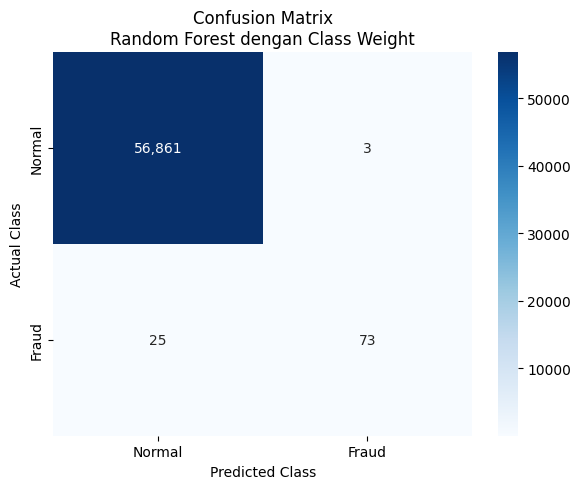

In [79]:
rf_class_weight = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_class_weight.fit(
    x_train_scaler,
    y_train
)

result_class_weight = evaluate_model(
    model_name="Random Forest dengan Class Weight",
    model=rf_class_weight,
    X_test=x_test_scaler,
    y_test=y_test
)

In [80]:
all_results = [
    hasil_rf_baseline,
    result_smote,
    result_class_weight
]

comparison_results = pd.DataFrame([
    {
        "Model": result["Model"],
        "Precision Fraud": result["Precision Fraud"],
        "Recall Fraud": result["Recall Fraud"],
        "F1-score Fraud": result["F1-score Fraud"],
        "ROC-AUC": result["ROC-AUC"],
        "PR-AUC": result["PR-AUC"],
        "False Positive": result["FP"],
        "False Negative": result["FN"],
        "True Positive": result["TP"]
    }
    for result in all_results
])

display(comparison_results.round(4))

,Model,Precision Fraud,Recall Fraud,F1-score Fraud,ROC-AUC,PR-AUC,False Positive,False Negative,True Positive
0,RandomForestClassifier tanpa smote,0.9412,0.8163,0.8743,0.9630,0.8734,5,18,80
1,Random Forest dengan SMOTE,0.8817,0.8367,0.8586,0.9642,0.8784,11,16,82
2,Random Forest dengan Class Weight,0.9605,0.7449,0.8391,0.9529,0.8539,3,25,73


In [81]:
thresholds = [0.3, 0.4, 0.5, 0.6]

threshold_results = []

y_proba_smote = result_smote["y_proba"]

for threshold in thresholds:
    y_pred_threshold = (
        y_proba_smote >= threshold
    ).astype(int)

    cm = confusion_matrix(
        y_test,
        y_pred_threshold
    )

    tn, fp, fn, tp = cm.ravel()

    threshold_results.append({
        "Threshold": threshold,
        "Precision Fraud": precision_score(
            y_test,
            y_pred_threshold,
            zero_division=0
        ),
        "Recall Fraud": recall_score(
            y_test,
            y_pred_threshold,
            zero_division=0
        ),
        "F1-score Fraud": f1_score(
            y_test,
            y_pred_threshold,
            zero_division=0
        ),
        "FP": fp,
        "FN": fn,
        "TP": tp
    })

threshold_df = pd.DataFrame(threshold_results)
display(threshold_df.round(4))

,Threshold,Precision Fraud,Recall Fraud,F1-score Fraud,FP,FN,TP
0,0.3,0.7073,0.8878,0.7873,36,11,87
1,0.4,0.8037,0.8776,0.8390,21,12,86
2,0.5,0.8817,0.8367,0.8586,11,16,82
3,0.6,0.9101,0.8265,0.8663,8,17,81
